# Clasificación de enfermedades en hojas de plantas con una CNN (PlantVillage)

**Evaluación Parcial N°2 - Deep Learning (DLY0100)**

## Introducción

**Problema:** queremos que un computador mire la foto de una hoja y diga si está sana o qué enfermedad tiene. Usamos el dataset **PlantVillage**, con fotos de hojas de pimentón, papa y tomate. Son **15 clases** (por ejemplo, *Tomato healthy*, *Potato Late blight* o *Tomato mosaic virus*). Es un problema de **clasificación de imágenes con varias clases**.

**Objetivo:** construir, entrenar y evaluar una **Red Neuronal Convolucional (CNN)** con TensorFlow/Keras, y mejorarla comparando distintas configuraciones.

**Qué hacemos en este notebook** (seguimos la misma estructura del ejemplo de clase *cómo entrenar una CNN*):
1. Cargar y preprocesar las imágenes.
2. Construir y entrenar un modelo base (Modelo A, de 2 capas convolucionales).
3. Comparar dos variantes de arquitectura: Modelo B (una capa convolucional más) y Modelo C (con Dropout).
4. Ajustar un hiperparámetro: el *learning rate*.
5. Evaluar el modelo final con accuracy, precision, recall y F1-score, y analizar sus errores.

Cada bloque de código va seguido de una explicación en tres partes: **qué muestra**, **qué significa** y **qué decisión tomamos y por qué**.

## Herramientas utilizadas

| Herramienta | Para qué la usamos | Fortaleza | Debilidad |
|---|---|---|---|
| **TensorFlow / Keras** | Construir y entrenar la CNN con `Sequential` | Pocas líneas de código y es la herramienta que vimos en clase | En Colab sin GPU entrena lento; por eso achicamos las imágenes |
| **Pillow (PIL)** | Abrir las fotos y achicarlas a 64x64 | Muy simple de usar | Hay que abrir las imágenes una por una, lo que limita cuántas podemos cargar |
| **NumPy y pandas** | Guardar las imágenes como arreglos y armar tablas de resultados | Rápidos y fáciles de leer | Tener todas las imágenes en memoria limita el tamaño del dataset |
| **scikit-learn** | Separar train/test y calcular precision, recall y F1 | Calcula las métricas de varias clases en una línea | Solo evalúa; no entrena la CNN |
| **Matplotlib y Seaborn** | Gráficos de curvas, matriz de confusión e imágenes | Permiten respaldar cada decisión con un gráfico | Hay que escribir varias líneas para cada gráfico |
| **Google Colab** | Ejecutar todo sin instalar nada | Gratis y listo para usar | La sesión es temporal: hay que volver a cargar los datos cada vez |

**Por qué Keras y no PyTorch:** es la herramienta que se explicó en clase y permite definir la CNN con muy poco código, lo que facilita entender y defender cada capa.

## 1. Importación de librerías y carga de datos

Importamos las librerías y cargamos las imágenes de PlantVillage desde sus carpetas: cada carpeta es una clase. Las fotos se achican a 64x64 píxeles y se guardan en un arreglo junto con su clase.

*(La primera celda de código es solo para Google Colab: descomprime el zip `PlantVillage_250.zip`, que contiene las 250 imágenes por clase que usamos.)*

In [ ]:
# SOLO EN GOOGLE COLAB: descomprimimos el zip con las imágenes.
# Antes hay que subir PlantVillage_250.zip al panel de archivos de Colab (carpeta /content).
!unzip -q /content/PlantVillage_250.zip -d /content/

# Si el zip está en Google Drive, usar en su lugar estas líneas (cambiar la ruta del zip):
# from google.colab import drive
# drive.mount('/content/drive')
# !unzip -q /content/drive/MyDrive/PlantVillage_250.zip -d /content/

In [1]:
import os # para recorrer las carpetas de imágenes
import numpy as np # sirve para trabajar con vectores en python
import pandas as pd # para trabajar con tablas
import matplotlib.pyplot as plt # para hacer gráficos y figuras
import seaborn as sns # para que los gráficos se vean mejor
from PIL import Image # para abrir y achicar las imágenes
from tensorflow import keras # para hacer modelos fáciles
from tensorflow.keras import layers # son las capas
from sklearn.model_selection import train_test_split # para separar train y test
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score # métricas para evaluar el modelo

# Dejamos fija la semilla para que los resultados se puedan repetir
keras.utils.set_random_seed(42)

In [2]:
# Carpeta con una subcarpeta por clase (cada subcarpeta es una enfermedad o planta sana)
RUTA = '/content/PlantVillage'

class_names = sorted(os.listdir(RUTA)) # nombres de las 15 clases
# Nombres más cortos y legibles para los gráficos
nombres = [c.replace('___', ' - ').replace('__', ' ').replace('_', ' ') for c in class_names]
print("Número de clases:", len(class_names))

X_raw = [] # aquí guardamos las imágenes
y_raw = [] # aquí guardamos la clase de cada imagen (0 a 14)

for numero, clase in enumerate(class_names):
    archivos = sorted(os.listdir(os.path.join(RUTA, clase)))[:250] # máximo 250 imágenes por clase
    for archivo in archivos:
        imagen = Image.open(os.path.join(RUTA, clase, archivo)).convert('RGB') # imagen a color
        imagen = imagen.resize((64, 64)) # la achicamos de 256x256 a 64x64 para entrenar más rápido
        X_raw.append(np.array(imagen))
        y_raw.append(numero)

X_raw = np.array(X_raw)
y_raw = np.array(y_raw)

print("Dimensiones de X_raw:", X_raw.shape)
print("Imágenes por clase:", np.bincount(y_raw))

Número de clases: 15


Dimensiones de X_raw: (3652, 64, 64, 3)
Imágenes por clase: [250 250 250 250 152 250 250 250 250 250 250 250 250 250 250]


**Qué muestra:** se leyeron 15 carpetas (clases) y las imágenes quedaron en un arreglo de forma `(3652, 64, 64, 3)`: 3.652 imágenes de 64x64 píxeles, a color (3 canales: rojo, verde y azul). Cada clase tiene 250 imágenes, excepto *Potato healthy*, que tiene 152 (es todo lo que trae su carpeta).

**Qué significa:** el problema es distinguir entre 15 clases que mezclan tres plantas y varias enfermedades. Las clases quedan casi equilibradas, así que ninguna domina a las demás.

**Decisión que tomamos y por qué:** usamos como máximo 250 imágenes por clase y las achicamos a 64x64. El dataset completo tiene 20.639 imágenes de 256x256 y entrenaría muy lento en Colab; en el ejemplo de clase también se usó un subconjunto pequeño para que fuera rápido. Poner un máximo por clase evita que las clases grandes (hasta 3.209 imágenes) dominen el entrenamiento. El costo es que al achicar las fotos se pierde algo de detalle.

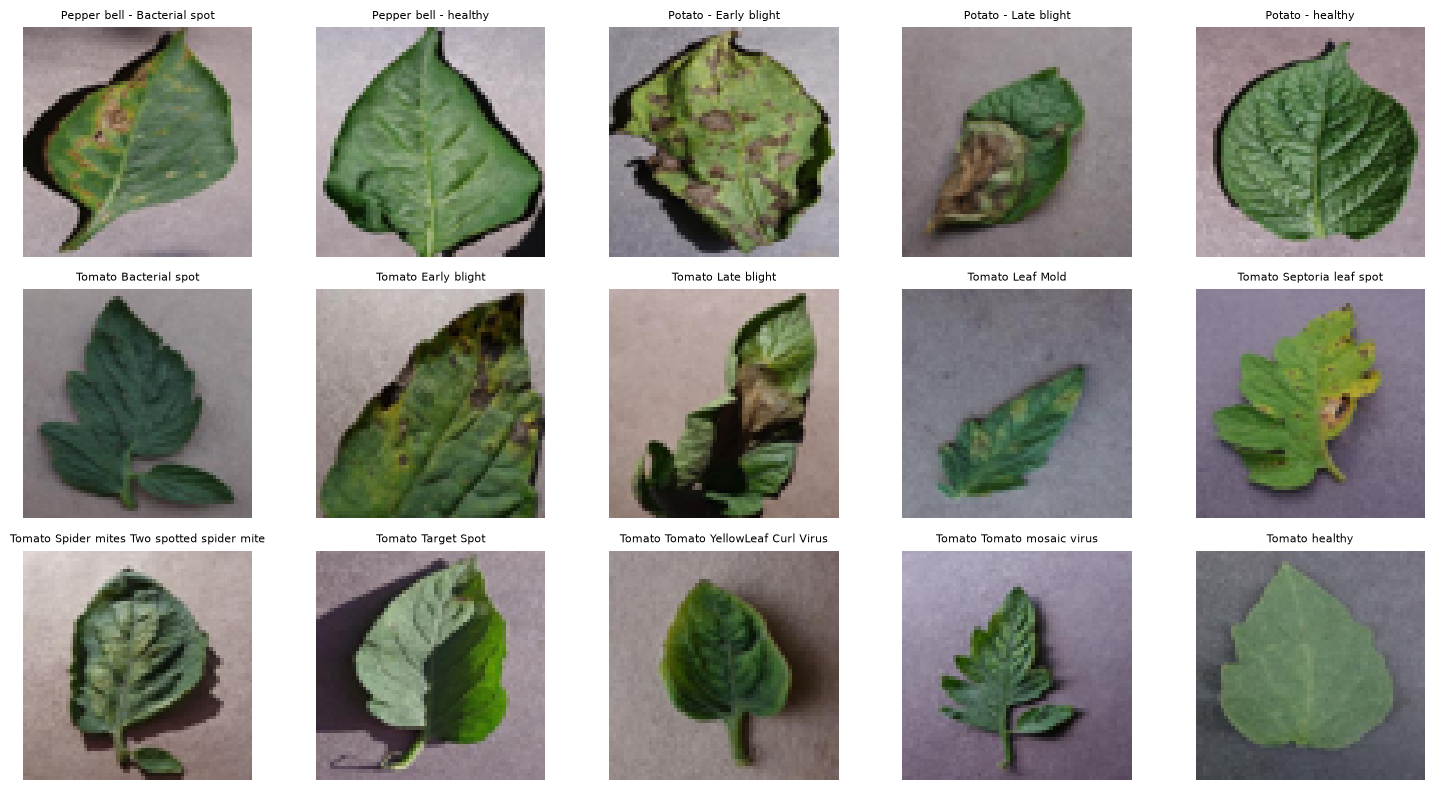

In [3]:
# Mostramos una imagen de cada clase
plt.figure(figsize=(15, 8))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_raw[np.where(y_raw == i)[0][0]])
    plt.title(nombres[i], fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

**Qué muestra:** una hoja de cada una de las 15 clases.

**Qué significa:** las hojas sanas se ven verdes y parejas; las enfermas tienen manchas, bordes secos o zonas café y amarillas. Pero algunas enfermedades se parecen entre sí (por ejemplo, las distintas manchas en hojas de tomate), así que ya podemos anticipar que algunas clases serán difíciles de separar.

**Decisión que tomamos y por qué:** trabajamos con color (RGB) y no con escala de grises, porque el color de las manchas (café, amarillo) es información clave para distinguir enfermedades. El ejemplo de clase usaba un solo canal porque sus imágenes eran en blanco y negro.

## 2. Preprocesamiento de datos

Separamos las imágenes en entrenamiento y test, normalizamos los píxeles y convertimos las etiquetas a *one-hot*.

In [4]:
# Separamos 80% para entrenar y 20% para test (con la misma proporción de cada clase)
X_train, X_test, y_train_raw, y_test_raw = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=42)

# Normalización de los píxeles a rango [0, 1]
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Conversión de etiquetas a vectores binarios (One-hot encoding)
num_classes = 15
y_train = keras.utils.to_categorical(y_train_raw, num_classes)
y_test = keras.utils.to_categorical(y_test_raw, num_classes)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Valor mínimo y máximo de los píxeles:", X_train.min(), X_train.max())
print("Ejemplo de etiqueta one-hot:", y_train[0])

X_train: (2921, 64, 64, 3) | X_test: (731, 64, 64, 3)
Valor mínimo y máximo de los píxeles: 0.0 1.0
Ejemplo de etiqueta one-hot: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


**Qué muestra:** `X_train` tiene 2.921 imágenes y `X_test` tiene 731. Los píxeles ahora van de 0.0 a 1.0 (antes de 0 a 255). Cada etiqueta es un vector de 15 posiciones con un 1 en la clase correcta y 0 en el resto.

**Qué significa:** el 80% de las imágenes se usa para entrenar y el 20% queda reservado para test. Más adelante, Keras separará una parte del entrenamiento para validación (unas 2.336 imágenes para entrenar y 585 para validar). Pixeles entre 0 y 1 ayudan a que el entrenamiento sea más estable, y el *one-hot* es el formato que necesitan la capa `softmax` de 15 salidas y la pérdida `categorical_crossentropy`.

**Decisión que tomamos y por qué:** usamos `stratify=y_raw` para que cada clase tenga la misma proporción en entrenamiento y test; esto importa sobre todo en *Potato healthy*, que tiene pocas imágenes. Además, `train_test_split` mezcla las imágenes: como Keras toma la validación del final de los datos, sin esa mezcla la validación tendría solo algunas clases. Dividimos por 255 y usamos *one-hot* igual que en el ejemplo de clase.

## 3. Construcción del modelo base (Modelo A)

Partimos de la CNN de 2 capas convolucionales del ejemplo de clase, adaptada a nuestras imágenes (64x64x3) y a nuestras 15 clases.

In [5]:
keras.utils.set_random_seed(42)

modelo_A = keras.Sequential([
    keras.Input(shape=(64, 64, 3)),
    # Primera capa convolucional
    layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Segunda capa convolucional
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Aplanamiento y capas densas
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# Compilación del modelo
modelo_A.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.Recall(name='recall')]
)

modelo_A.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 823,247 (3.14 MB)

 Trainable params: 823,247 (3.14 MB)

 Non-trainable params: 0 (0.00 B)

**Qué muestra:** el resumen del modelo A. La imagen de entrada (64x64x3) pasa por: convolución de 32 filtros (62x62x32) → pooling (31x31x32) → convolución de 64 filtros (29x29x64) → pooling (14x14x64) → `Flatten` (12.544 valores) → capa densa de 64 neuronas → capa de salida de 15 neuronas con `softmax`. En total tiene **823.247 parámetros**.

**Qué significa:** las capas convolucionales detectan patrones en la imagen (bordes, manchas, texturas), el pooling resume la información y achica la imagen, `Flatten` la convierte en una lista de números y las capas densas deciden la clase. La salida `softmax` entrega 15 probabilidades que suman 1. Casi todos los parámetros (802.880 de 823.247) están en la primera capa densa; las dos convolucionales suman solo 19.392.

**Decisión que tomamos y por qué:** partimos con la misma estructura del ejemplo de clase, que ya conocemos y podemos defender, y solo cambiamos la forma de entrada (64x64x3) y la salida (15 clases con `softmax`). Compilamos con `adam`, `categorical_crossentropy` (clasificación de varias clases con etiquetas *one-hot*) y las métricas accuracy y recall, igual que en clase.

## 4. Entrenamiento del modelo A

Entrenamos 12 épocas, con lotes de 64 imágenes. Dejamos el 20% de las imágenes de entrenamiento para validación (`validation_split=0.2`) y guardamos el progreso en `history_A`.

In [6]:
history_A = modelo_A.fit(
    X_train, y_train,
    epochs=12,
    batch_size=64,
    validation_split=0.2,
    verbose=2
)

Epoch 1/12


37/37 - 3s - 81ms/step - accuracy: 0.2423 - loss: 2.3886 - recall: 0.0180 - val_accuracy: 0.3453 - val_loss: 1.9916 - val_recall: 0.1077


Epoch 2/12


37/37 - 2s - 51ms/step - accuracy: 0.4580 - loss: 1.6868 - recall: 0.1879 - val_accuracy: 0.4718 - val_loss: 1.5737 - val_recall: 0.2017


Epoch 3/12


37/37 - 2s - 52ms/step - accuracy: 0.5719 - loss: 1.3236 - recall: 0.3455 - val_accuracy: 0.5265 - val_loss: 1.4389 - val_recall: 0.3009


... (14 outputs left out)

Epoch 11/12


37/37 - 2s - 53ms/step - accuracy: 0.9067 - loss: 0.3137 - recall: 0.8720 - val_accuracy: 0.5897 - val_loss: 1.4111 - val_recall: 0.5453


Epoch 12/12


37/37 - 2s - 57ms/step - accuracy: 0.9084 - loss: 0.2869 - recall: 0.8741 - val_accuracy: 0.6684 - val_loss: 1.1270 - val_recall: 0.6085


**Qué muestra:** el entrenamiento de 12 épocas. El accuracy de entrenamiento sube de 0.24 en la primera época hasta 0.91 en la última. El accuracy de validación termina en 0.668 y su loss en 1.127.

**Qué significa:** el modelo aprende muy bien las imágenes con las que entrena, pero rinde bastante peor con imágenes que no ve: hay una brecha de unos 24 puntos entre entrenamiento (0.91) y validación (0.67). Eso se llama **sobreajuste**: el modelo empieza a memorizar en lugar de aprender patrones generales.

**Decisión que tomamos y por qué:** mantenemos 12 épocas y lotes de 64, como en el ejemplo de clase. Tomamos este resultado como punto de partida y, desde aquí, decidimos siempre mirando la validación (no el test), para no ajustar el modelo a las imágenes con las que lo vamos a evaluar al final.

## 5. Curvas de Accuracy, Loss y Recall del modelo A

Graficamos cómo evolucionan las métricas por época, en entrenamiento y en validación.

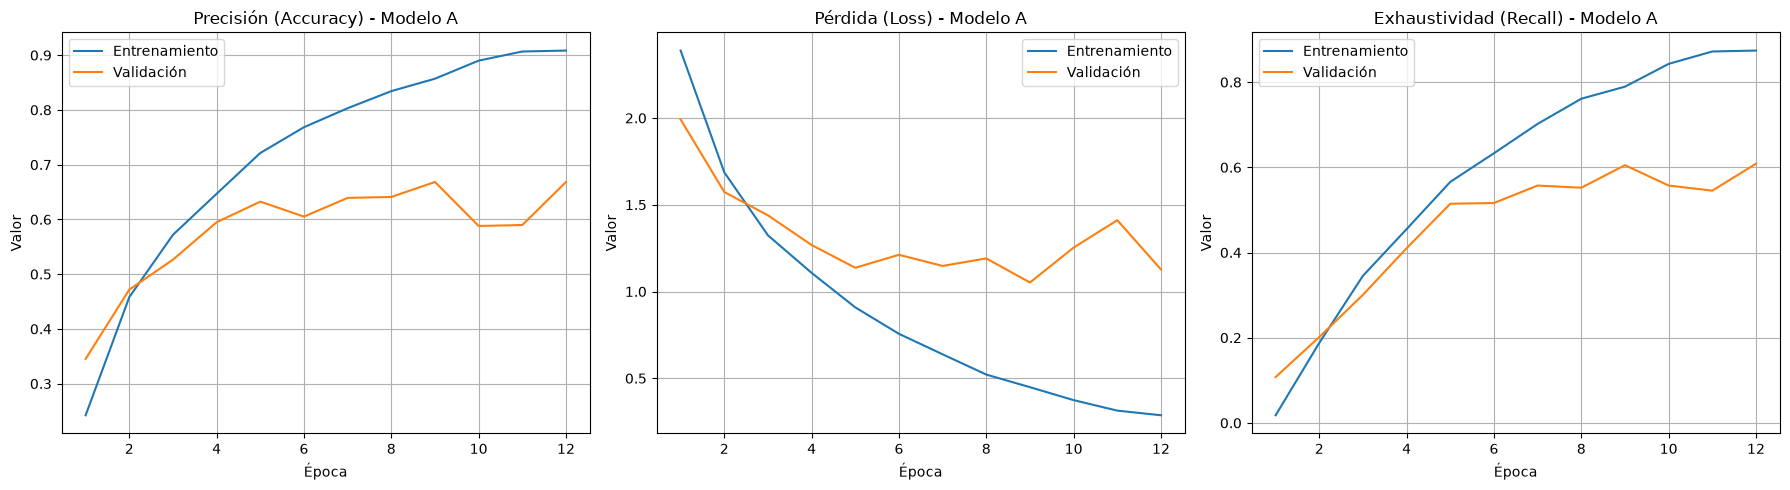

In [7]:
epochs_range = range(1, 13)

plt.figure(figsize=(18, 5))

# Gráfico de Accuracy
plt.subplot(1, 3, 1)
plt.plot(epochs_range, history_A.history['accuracy'], label='Entrenamiento')
plt.plot(epochs_range, history_A.history['val_accuracy'], label='Validación')
plt.title('Precisión (Accuracy) - Modelo A')
plt.xlabel('Época')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)

# Gráfico de Loss
plt.subplot(1, 3, 2)
plt.plot(epochs_range, history_A.history['loss'], label='Entrenamiento')
plt.plot(epochs_range, history_A.history['val_loss'], label='Validación')
plt.title('Pérdida (Loss) - Modelo A')
plt.xlabel('Época')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)

# Gráfico de Recall
plt.subplot(1, 3, 3)
plt.plot(epochs_range, history_A.history['recall'], label='Entrenamiento')
plt.plot(epochs_range, history_A.history['val_recall'], label='Validación')
plt.title('Exhaustividad (Recall) - Modelo A')
plt.xlabel('Época')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Qué muestra:** tres gráficos del modelo A. En accuracy, la curva de entrenamiento sube sin parar, pero la de validación se estanca alrededor de 0.60-0.67 desde la época 5 y oscila. En loss, el entrenamiento baja hasta 0.29, pero la validación deja de bajar desde la época 5 (queda cerca de 1.1) y sube en las épocas 10 y 11. El recall se comporta igual que el accuracy.

**Qué significa:** que las curvas se separen es la señal visual del sobreajuste. Entrenar más épocas no ayudaría al modelo A: la validación ya dejó de mejorar. Además, la validación sube y baja de una época a otra (el accuracy pasa de 0.67 a 0.59), así que el resultado de una sola época es algo ruidoso.

**Decisión que tomamos y por qué:** buscamos reducir el sobreajuste cambiando la arquitectura. Probamos dos ideas simples, cada una por separado: una capa convolucional más (modelo B) y Dropout (modelo C).

## 6. Comparación de arquitecturas

Probamos dos variantes del modelo A. En cada una cambiamos **una sola cosa**, para saber qué cambio produjo cada efecto:

- **Modelo B:** una tercera capa convolucional (128 filtros).
- **Modelo C:** una capa Dropout del 50%.

Los tres se entrenan con la misma configuración (12 épocas, lotes de 64, `adam` con `learning_rate` 0.001).

In [8]:
keras.utils.set_random_seed(42)

# Modelo B: igual que el A, pero con una tercera capa convolucional (128 filtros)
modelo_B = keras.Sequential([
    keras.Input(shape=(64, 64, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'), # capa nueva
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

modelo_B.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.Recall(name='recall')]
)

print("Parámetros del modelo B:", modelo_B.count_params())

Parámetros del modelo B: 389199


**Qué muestra:** el modelo B tiene 389.199 parámetros, menos que el A (823.247), aunque tiene una capa más.

**Qué significa:** con una tercera convolución y su pooling, la imagen llega a la capa `Flatten` como 6x6x128 = 4.608 valores (en el modelo A eran 12.544). Por eso la capa densa es mucho más pequeña. El modelo B extrae patrones más complejos con menos parámetros, y tener menos parámetros reduce la capacidad de memorizar.

**Decisión que tomamos y por qué:** agregamos una capa con 128 filtros siguiendo el patrón de ir aumentando los filtros (32 → 64 → 128). Es una modificación simple, que se explica fácil, y dejamos todo lo demás igual al modelo A para que la comparación sea justa.

In [9]:
keras.utils.set_random_seed(42)

# Modelo C: igual que el A, pero con Dropout del 50% antes de la capa final
modelo_C = keras.Sequential([
    keras.Input(shape=(64, 64, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5), # capa nueva: apaga el 50% de las neuronas al azar al entrenar
    layers.Dense(num_classes, activation='softmax')
])

modelo_C.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.Recall(name='recall')]
)

print("Parámetros del modelo C:", modelo_C.count_params())

Parámetros del modelo C: 823247


**Qué muestra:** el modelo C tiene 823.247 parámetros, exactamente los mismos que el A.

**Qué significa:** `Dropout` no agrega parámetros. Lo que hace es apagar al azar el 50% de las neuronas de la capa anterior en cada paso de entrenamiento, para que la red no dependa de unas pocas neuronas. Solo actúa al entrenar; al predecir se usan todas.

**Decisión que tomamos y por qué:** lo ubicamos justo después de la capa densa de 64 neuronas, que es la que concentra casi todos los parámetros y donde el modelo A memoriza. Usamos 0.5, un valor de uso habitual, para no agregar otro hiperparámetro que justificar.

In [10]:
# Entrenamos B y C con exactamente la misma configuración que A
history_B = modelo_B.fit(X_train, y_train, epochs=12, batch_size=64, validation_split=0.2, verbose=0)
history_C = modelo_C.fit(X_train, y_train, epochs=12, batch_size=64, validation_split=0.2, verbose=0)

print("Entrenamiento terminado")
print("Accuracy de validación en la última época -> A:", round(history_A.history['val_accuracy'][-1], 3),
      "| B:", round(history_B.history['val_accuracy'][-1], 3),
      "| C:", round(history_C.history['val_accuracy'][-1], 3))

Entrenamiento terminado
Accuracy de validación en la última época -> A: 0.668 | B: 0.706 | C: 0.639


**Qué muestra:** B y C terminaron de entrenar. El accuracy de validación en la última época fue: A = 0.668, B = 0.706 y C = 0.639.

**Qué significa:** B queda arriba al final, pero las diferencias son pequeñas y la validación oscila de una época a otra, así que no basta con mirar un solo número: hay que ver las curvas completas.

**Decisión que tomamos y por qué:** entrenamos B y C con exactamente la misma configuración que A (12 épocas, lotes de 64, misma validación y misma semilla). Así, cualquier diferencia se debe solo a la arquitectura. Usamos `verbose=0` para no llenar la pantalla con el detalle de cada época.

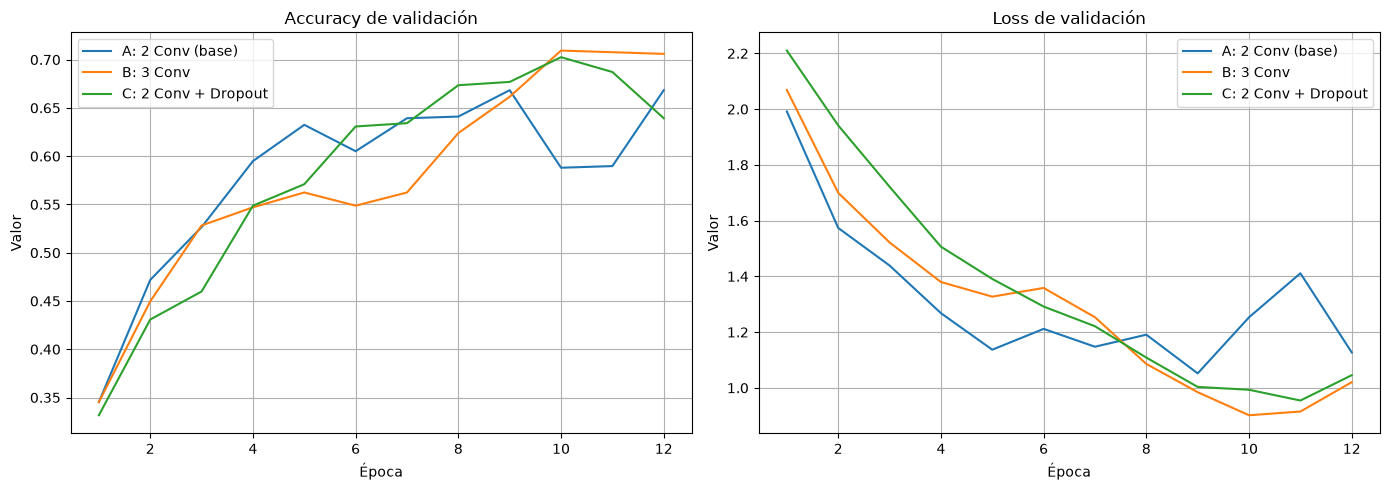

In [11]:
plt.figure(figsize=(14, 5))

# Accuracy de validación de los tres modelos
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_A.history['val_accuracy'], label='A: 2 Conv (base)')
plt.plot(epochs_range, history_B.history['val_accuracy'], label='B: 3 Conv')
plt.plot(epochs_range, history_C.history['val_accuracy'], label='C: 2 Conv + Dropout')
plt.title('Accuracy de validación')
plt.xlabel('Época')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)

# Loss de validación de los tres modelos
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_A.history['val_loss'], label='A: 2 Conv (base)')
plt.plot(epochs_range, history_B.history['val_loss'], label='B: 3 Conv')
plt.plot(epochs_range, history_C.history['val_loss'], label='C: 2 Conv + Dropout')
plt.title('Loss de validación')
plt.xlabel('Época')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Qué muestra:** el accuracy y el loss de validación de los tres modelos. En accuracy, los tres parten cerca de 0.33-0.35. B y C llegan a cerca de 0.70-0.71 en la época 10, mientras que A llega a 0.67 en la época 9 y luego cae a 0.59. En loss, A sube en las épocas 10 y 11 (1.25 y 1.41), mientras que B y C bajan de forma más pareja: el mínimo de B es 0.90 (época 10) y el de C es 0.95 (época 11). Al final, C baja a 0.64 de accuracy.

**Qué significa:** el modelo A es el más inestable y el que más sobreajusta. B y C lo reducen: B logra el menor loss y el mayor accuracy de validación, y C tiene un loss estable, pero su accuracy cae en la última época.

**Decisión que tomamos y por qué:** B es el mejor candidato porque tiene el mejor accuracy y el menor loss en validación. C queda segundo.

In [12]:
# Tabla con lo que pasó en la última época de entrenamiento
tabla_val = pd.DataFrame({
    'Modelo': ['A: 2 Conv (base)', 'B: 3 Conv', 'C: 2 Conv + Dropout'],
    'Parámetros': [modelo_A.count_params(), modelo_B.count_params(), modelo_C.count_params()],
    'Accuracy entrenamiento': [history_A.history['accuracy'][-1], history_B.history['accuracy'][-1], history_C.history['accuracy'][-1]],
    'Accuracy validación': [history_A.history['val_accuracy'][-1], history_B.history['val_accuracy'][-1], history_C.history['val_accuracy'][-1]],
    'Loss validación': [history_A.history['val_loss'][-1], history_B.history['val_loss'][-1], history_C.history['val_loss'][-1]]
}).round(3)

tabla_val

,Modelo,Parámetros,Accuracy entrenamiento,Accuracy validación,Loss validación
0,A: 2 Conv (base),823247,0.908,0.668,1.127
1,B: 3 Conv,389199,0.856,0.706,1.020
2,C: 2 Conv + Dropout,823247,0.674,0.639,1.045


**Qué muestra:** la tabla con la última época de cada modelo. A: entrenamiento 0.908, validación 0.668, loss 1.127. B: 0.856, 0.706 y 1.020. C: 0.674, 0.639 y 1.045.

**Qué significa:** la brecha entre entrenamiento y validación es de 0.24 en A, 0.15 en B y solo 0.04 en C. B tiene el mayor accuracy de validación y el menor loss. C casi no tiene brecha porque Dropout frena la memorización, pero su accuracy de entrenamiento es bajo (0.674; con Dropout se mide con neuronas apagadas) y tampoco mejora la validación: con solo 12 épocas aprende más lento.

**Decisión que tomamos y por qué:** elegimos B como arquitectura. La decisión se toma con la validación, que es justamente para eso, y no con el test.

In [13]:
# Evaluamos los tres modelos con las imágenes de test (que no vieron al entrenar)
filas = []
for nombre, modelo in [('A: 2 Conv (base)', modelo_A), ('B: 3 Conv', modelo_B), ('C: 2 Conv + Dropout', modelo_C)]:
    y_pred = np.argmax(modelo.predict(X_test, verbose=0), axis=1)
    filas.append([nombre,
                  accuracy_score(y_test_raw, y_pred),
                  precision_score(y_test_raw, y_pred, average='macro', zero_division=0),
                  recall_score(y_test_raw, y_pred, average='macro'),
                  f1_score(y_test_raw, y_pred, average='macro')])

tabla_test = pd.DataFrame(filas, columns=['Modelo', 'Accuracy', 'Precision', 'Recall', 'F1-score']).round(3)
tabla_test

,Modelo,Accuracy,Precision,Recall,F1-score
0,A: 2 Conv (base),0.661,0.724,0.661,0.668
1,B: 3 Conv,0.688,0.729,0.693,0.695
2,C: 2 Conv + Dropout,0.672,0.695,0.675,0.664


**Qué muestra:** accuracy, precision, recall y F1-score de los tres modelos en test. A: 0.661 / 0.724 / 0.661 / 0.668. B: 0.688 / 0.729 / 0.693 / 0.695. C: 0.672 / 0.695 / 0.675 / 0.664 (precision, recall y F1 son promedios *macro*: se calculan por clase y se promedian, de modo que las 15 clases pesan igual).

**Qué significa:** B es el mejor en las cuatro métricas. La *precision* es mayor que el *recall* en los tres modelos: cuando el modelo asigna una clase suele acertar más de lo que logra encontrar todos los casos de esa clase.

**Decisión que tomamos y por qué:** el test confirma la elección de B que hicimos con la validación. Como el test tiene solo 731 imágenes y la diferencia con los otros modelos es de 2 a 3 puntos de F1, somos prudentes: no decimos que B sea mucho mejor, sino que fue consistentemente mejor y más estable.

## 7. Ajuste de hiperparámetros: learning rate

El *learning rate* es el tamaño del paso con que el modelo corrige sus errores en cada actualización. Lo probamos con 3 valores (0.01, 0.001 y 0.0001) usando la mejor arquitectura de la sección anterior.

In [14]:
# Probamos tres learning rate en la arquitectura B (la mejor de la sección anterior)
resultados_lr = []
history_lr = {}
modelos_lr = {}

for lr in [0.01, 0.001, 0.0001]:
    keras.utils.set_random_seed(42)

    modelo = keras.Sequential([
        keras.Input(shape=(64, 64, 3)),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr), # aquí cambiamos el learning rate
        loss='categorical_crossentropy',
        metrics=['accuracy', keras.metrics.Recall(name='recall')]
    )

    history = modelo.fit(X_train, y_train, epochs=12, batch_size=64, validation_split=0.2, verbose=0)
    y_pred = np.argmax(modelo.predict(X_test, verbose=0), axis=1)

    history_lr[lr] = history
    modelos_lr[lr] = modelo
    resultados_lr.append([str(lr), history.history['accuracy'][-1], history.history['val_accuracy'][-1],
                          history.history['val_loss'][-1], f1_score(y_test_raw, y_pred, average='macro')])

tabla_lr = pd.DataFrame(resultados_lr, columns=['Learning rate', 'Accuracy entrenamiento', 'Accuracy validación', 'Loss validación', 'F1-score test']).round(3)
tabla_lr

,Learning rate,Accuracy entrenamiento,Accuracy validación,Loss validación,F1-score test
0,0.01,0.625,0.487,1.682,0.498
1,0.001,0.856,0.706,1.020,0.695
2,0.0001,0.561,0.528,1.454,0.508


**Qué muestra:** la arquitectura B entrenada con tres learning rate. Con 0.01: validación 0.487, loss 1.682 y F1 en test 0.498. Con 0.001: 0.706, 1.020 y 0.695. Con 0.0001: 0.528, 1.454 y 0.508.

**Qué significa:** con 0.01 el paso es demasiado grande y el modelo no logra afinar (se estanca en 0.49). Con 0.0001 el paso es demasiado pequeño y, en 12 épocas, aprende poco. Con 0.001, que es el valor por defecto de `adam`, el rendimiento es claramente el mejor.

**Decisión que tomamos y por qué:** nos quedamos con **learning rate = 0.001**. Probamos un valor 10 veces mayor y otro 10 veces menor para ver la tendencia con pocas pruebas.

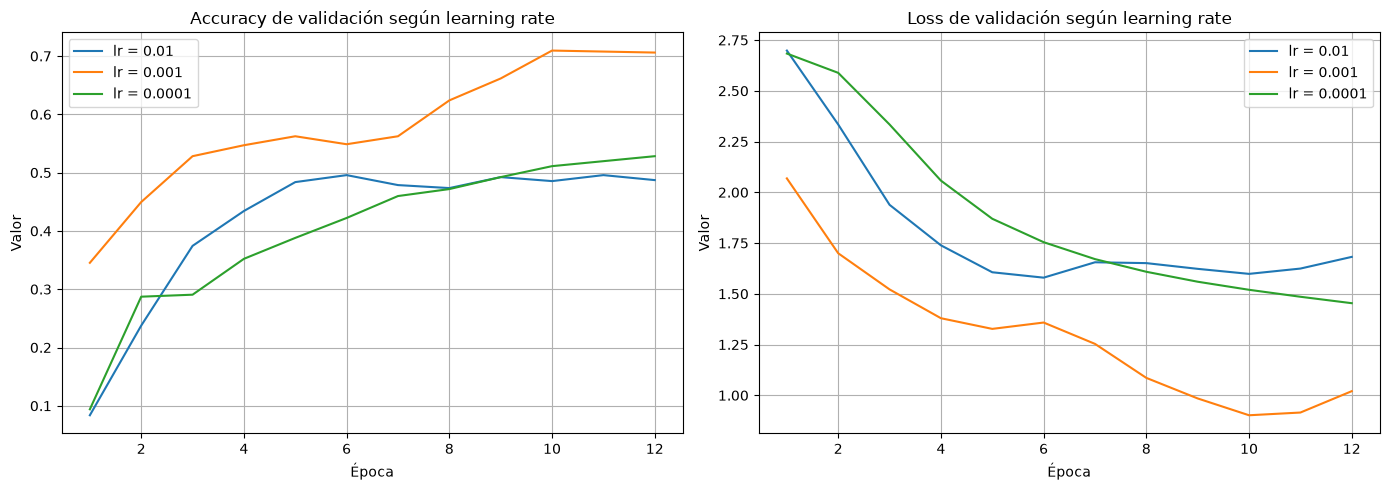

In [15]:
plt.figure(figsize=(14, 5))

# Accuracy de validación con cada learning rate
plt.subplot(1, 2, 1)
for lr in [0.01, 0.001, 0.0001]:
    plt.plot(epochs_range, history_lr[lr].history['val_accuracy'], label='lr = ' + str(lr))
plt.title('Accuracy de validación según learning rate')
plt.xlabel('Época')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)

# Loss de validación con cada learning rate
plt.subplot(1, 2, 2)
for lr in [0.01, 0.001, 0.0001]:
    plt.plot(epochs_range, history_lr[lr].history['val_loss'], label='lr = ' + str(lr))
plt.title('Loss de validación según learning rate')
plt.xlabel('Época')
plt.ylabel('Valor')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Qué muestra:** el learning rate 0.001 (naranja) sube más rápido y llega a 0.71 de accuracy de validación; su loss baja hasta 0.90 en la época 10. Con 0.01 el accuracy sube rápido al principio pero se queda cerca de 0.49 y el loss se estanca en torno a 1.6. Con 0.0001 el accuracy sube lento pero sin parar hasta 0.53, y su loss todavía estaba bajando al final (1.45).

**Qué significa:** con 0.0001 el modelo podría seguir mejorando si entrenara muchas más épocas, pero tardaría mucho más; con 0.01 no mejoraría aunque entrenara más. Este ajuste fue el que más cambió el resultado: de 0.49 a 0.71 de accuracy de validación (22 puntos), mientras que cambiar de arquitectura (A → B) mejoró unos 4 puntos de validación y 3 de F1 en test.

**Decisión que tomamos y por qué:** el **modelo final es la arquitectura B con learning rate 0.001**. Con las curvas y las tablas queda respaldado: tiene el mejor accuracy y el menor loss de validación, y también el mejor F1 en test entre todas las configuraciones probadas.

## 8. Evaluación del modelo final en el conjunto de test

Evaluamos el modelo elegido con las imágenes de test, que el modelo nunca vio al entrenar ni al validar.

In [16]:
# Modelo final: arquitectura B con learning rate 0.001
modelo_final = modelos_lr[0.001]

# Predicciones sobre el conjunto de test
y_pred_probs = modelo_final.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test_raw

print(classification_report(y_true, y_pred, target_names=nombres, zero_division=0))

                                             precision    recall  f1-score   support

               Pepper bell - Bacterial spot       0.48      0.80      0.60        50
                      Pepper bell - healthy       0.77      0.66      0.71        50
                      Potato - Early blight       0.89      0.84      0.87        50
                       Potato - Late blight       0.62      0.50      0.56        50
                           Potato - healthy       0.59      0.87      0.70        31
                      Tomato Bacterial spot       0.83      0.58      0.68        50
                        Tomato Early blight       0.39      0.60      0.48        50
                         Tomato Late blight       0.90      0.56      0.69        50
                           Tomato Leaf Mold       0.77      0.80      0.78        50
                  Tomato Septoria leaf spot       0.62      0.48      0.54        50
Tomato Spider mites Two spotted spider mite       0.86      0.64

**Qué muestra:** precision, recall y F1-score de cada clase en test, y el accuracy total: 0.69 (503 aciertos de 731 imágenes). Las mejores clases son *Potato Early blight* (F1 0.87), *Tomato mosaic virus* (0.87, con precision 0.97), *Tomato healthy* (0.83, con precision 0.97) y *Tomato YellowLeaf Curl Virus* (0.81, con recall 0.92). Las peores son *Tomato Early blight* (F1 0.48), *Tomato Septoria leaf spot* (0.54), *Potato Late blight* (0.56) y *Tomato Target Spot* (0.58).

**Qué significa:** *precision* es, de todo lo que el modelo dice que es una clase, cuánto realmente lo es; *recall* es, de todos los casos reales de una clase, cuántos encuentra. *Pepper bell - Bacterial spot* tiene recall alto (0.80) pero precision baja (0.48): el modelo usa esa clase como "comodín" y se la asigna a muchas imágenes que no lo son. Pasa algo parecido con *Tomato Early blight* (precision 0.39). En cambio, *Tomato healthy* tiene precision 0.97 pero recall 0.72: cuando dice que está sana casi siempre acierta, pero deja varias hojas sanas clasificadas en otra clase.

**Decisión que tomamos y por qué:** además del accuracy reportamos el F1-score *macro* (0.69), porque junta precision y recall y trata todas las clases por igual (una clase, *Potato healthy*, tiene menos imágenes de test: 31). Mirar solo el accuracy ocultaría las diferencias entre clases que vemos en esta tabla.

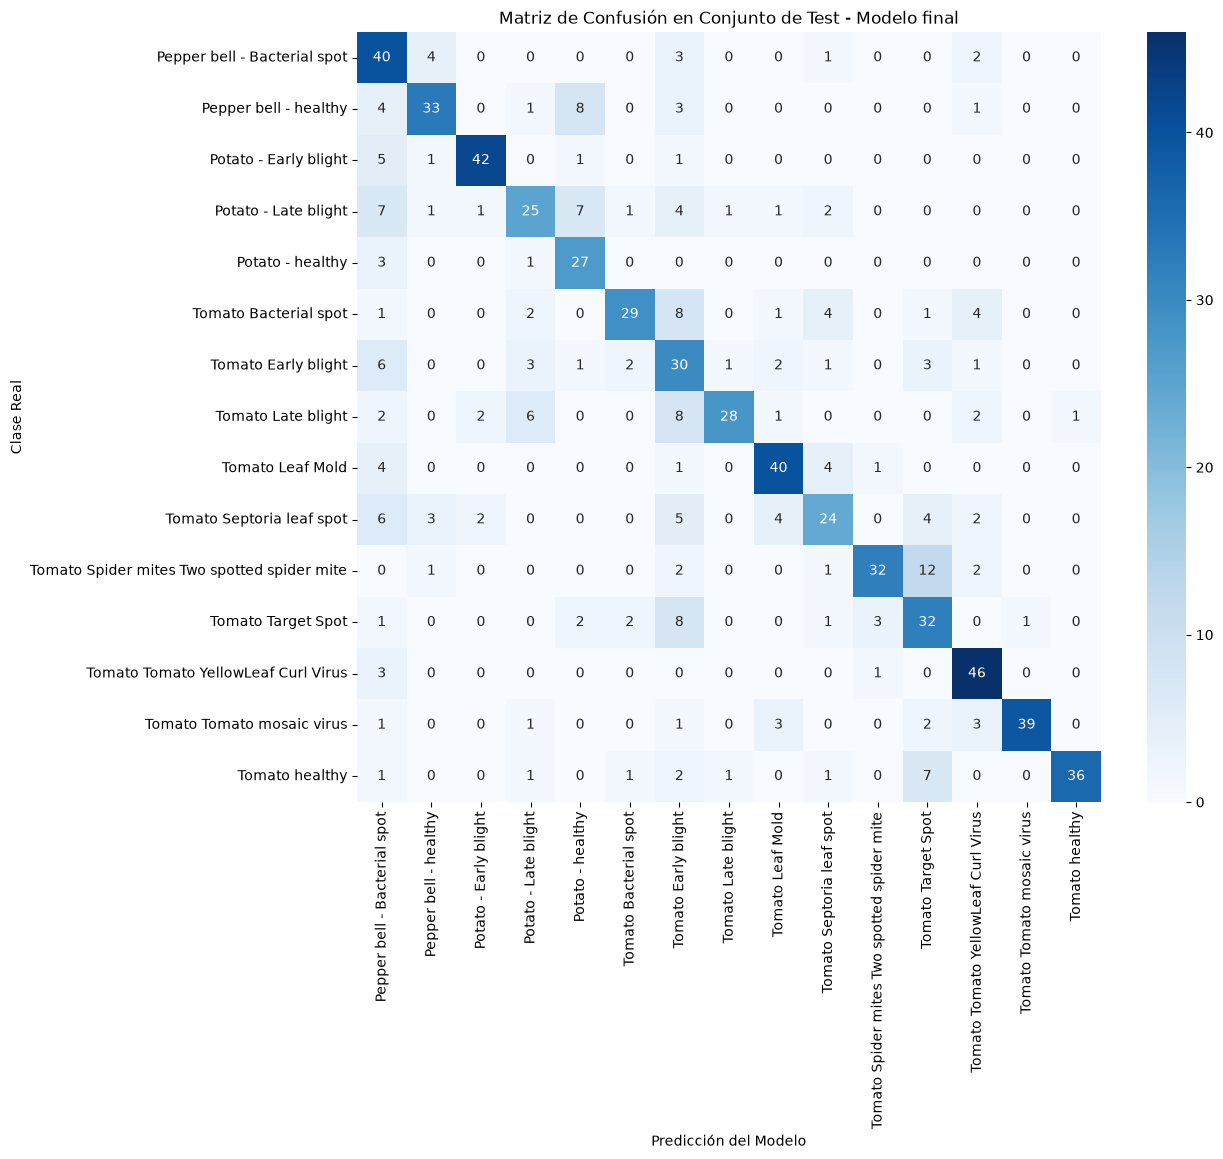

In [17]:
# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=nombres, yticklabels=nombres)
plt.title('Matriz de Confusión en Conjunto de Test - Modelo final')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Clase Real')
plt.xticks(rotation=90)
plt.show()

**Qué muestra:** la matriz de confusión del modelo final: las filas son la clase real y las columnas la clase que predijo el modelo. La diagonal son los aciertos (503 en total). Las confusiones más grandes son: *Spider mites* clasificadas como *Target Spot* (12 de 50); *Tomato Bacterial spot*, *Tomato Late blight* y *Tomato Target Spot* clasificadas como *Tomato Early blight* (8 cada una); *Pepper bell healthy* como *Potato healthy* (8); y *Potato Late blight* como *Pepper bell Bacterial spot* (7) y como *Potato healthy* (7).

**Qué significa:** los errores no son al azar. Ocurren entre clases que se parecen, sobre todo enfermedades de las hojas de tomate entre sí (manchas similares) y hojas sanas de plantas distintas. *Tomato Early blight* actúa como clase "comodín" para otras enfermedades del tomate con manchas, y eso explica su baja precision.

**Decisión que tomamos y por qué:** no cambiamos el modelo después de ver el test, porque eso nos haría ajustarlo a esas imágenes. Dejamos estas confusiones como limitaciones y como guía de qué mejorar más adelante (más datos o imágenes de mayor tamaño).

Errores en test: 228 de 731


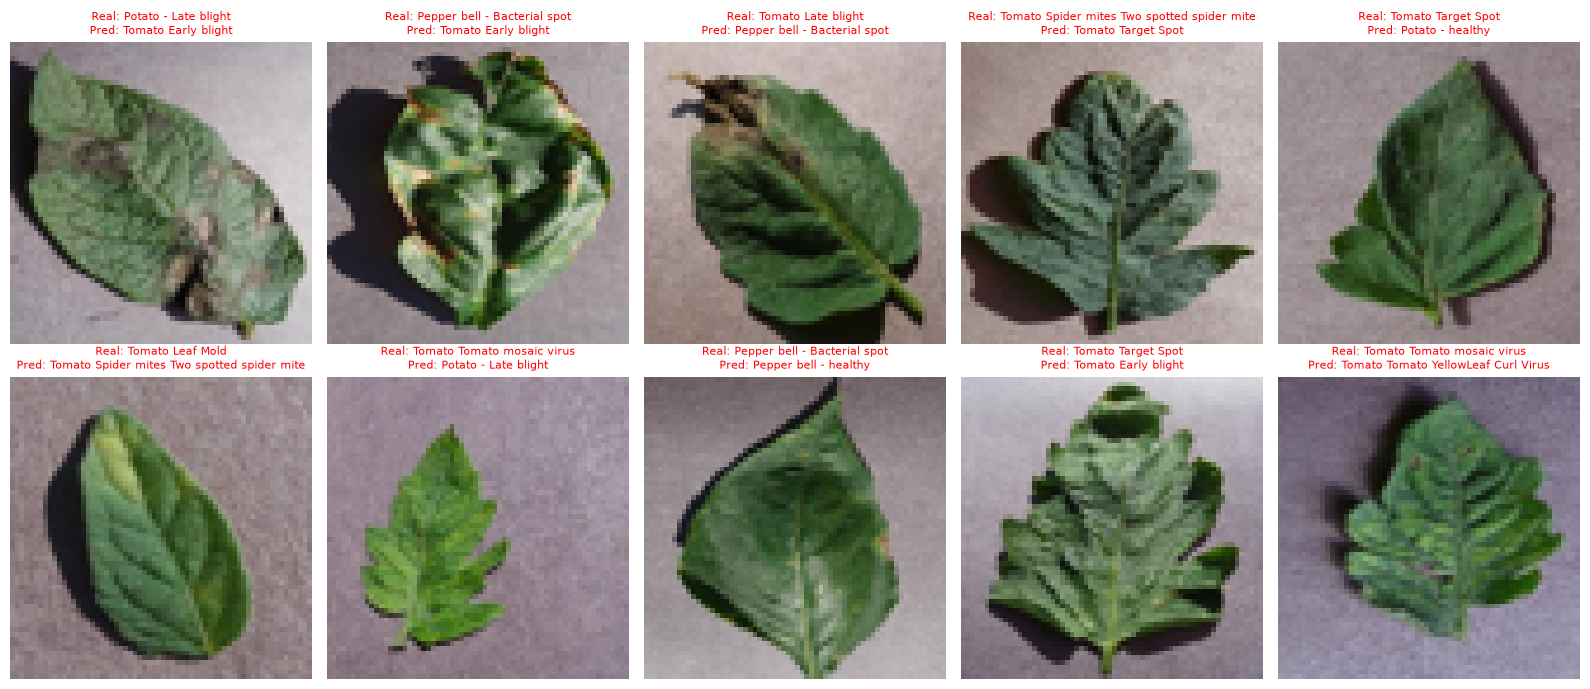

In [18]:
# Imágenes que el modelo clasificó mal (mostramos 10)
errores_indices = np.where(y_pred != y_true)[0]
print("Errores en test:", len(errores_indices), "de", len(y_true))

plt.figure(figsize=(16, 7))
for i, index in enumerate(errores_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[index])
    plt.title("Real: " + nombres[y_true[index]] + "\nPred: " + nombres[y_pred[index]], color='red', fontsize=8)
    plt.axis('off')

plt.tight_layout()
plt.show()

**Qué muestra:** hubo 228 errores en 731 imágenes de test (31%). Mostramos 10 de ellos con su clase real y la predicha.

**Qué significa:** en varios casos la hoja casi no muestra síntomas visibles o tiene manchas parecidas a las de otra enfermedad; a 64x64 píxeles esos detalles pequeños se pierden. Es coherente con lo que vimos en la matriz de confusión.

**Decisión que tomamos y por qué:** consideramos aceptable este nivel de error para el alcance de la prueba. Achicar las imágenes y usar un subconjunto fue una decisión deliberada para que el entrenamiento fuera rápido, y sabemos que tiene este costo.

## 9. Conclusiones

**Qué hicimos:** construimos una CNN para clasificar 15 tipos de hojas (sanas y enfermas) de PlantVillage, partiendo del modelo de 2 capas convolucionales de clase (modelo A), y lo comparamos con dos variantes (B: 3 capas convolucionales; C: con Dropout) y con tres valores de learning rate.

**Resultados principales:**

- El modelo base (A) sobreajustó: 0.91 de accuracy en entrenamiento contra 0.67 en validación.
- La mejor arquitectura fue **B (3 capas convolucionales)**: mejor accuracy y loss de validación y mejores accuracy, precision, recall y F1 en test, con casi la mitad de los parámetros de A.
- El mejor learning rate fue **0.001**. Fue el ajuste con más efecto: de 0.49 a 0.71 de accuracy de validación.
- **Modelo final: arquitectura B + learning rate 0.001**, con accuracy 0.69 y F1-score macro 0.69 en test.

**Qué aprendimos:**

- El learning rate pesó más que el cambio de arquitectura: una mala elección dejó al modelo en 0.49 de accuracy.
- Dropout redujo el sobreajuste (brecha de solo 0.04), pero en 12 épocas no mejoró la validación.
- El accuracy por sí solo no cuenta toda la historia: el reporte por clase mostró que algunas clases (como *Tomato Early blight*) funcionan mucho peor que otras.
- Los errores se concentran entre enfermedades de aspecto parecido.

**Limitaciones:** usamos un subconjunto (máx. 250 imágenes por clase), imágenes de 64x64 y 12 épocas, y entrenamos cada configuración una sola vez, por lo que las diferencias pequeñas (2 a 3 puntos) no son concluyentes.

**Posibles mejoras (no aplicadas aquí):** usar más imágenes por clase, probar imágenes de mayor tamaño (por ejemplo, 128x128) y entrenar más épocas con un learning rate menor.